# Importing libraries

In [1]:
import foldersfiles as ff
import functions as fn

import numpy as np
import pandas as pd
import math

import json

from pathlib import Path

import pickle

# Importing data

In [2]:
df = fn.import_func(
    ff.CLEANED_ORIGINALS_DATA_DIR / ff.PARQUETS / f'{ff.EUMACO}-all.parquet'
)

Drop `json_id` and `transm_id` columns

In [3]:
# df = df[[
#     'pseudopaz' ,
#     # 'json_id' ,
#     # 'transm_id' ,
#     'datetime' ,
#     'syst_bp_mmhg' ,
#     'diast_bp_mmhg' ,
#     'map_mmhg' ,
#     'hr_bpm' ,
#     'hr_source' ,
#     'spo2_pct' ,
#     'weight_kg' ,
# ]]

# Analysis

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27960 entries, 0 to 27959
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   pseudopaz      27960 non-null  str           
 1   json_id        27960 non-null  int64         
 2   transm_id      27960 non-null  int64         
 3   datetime       27960 non-null  datetime64[us]
 4   syst_bp_mmhg   11139 non-null  float64       
 5   diast_bp_mmhg  11139 non-null  float64       
 6   map_mmhg       11139 non-null  float64       
 7   hr_bpm         19292 non-null  float64       
 8   hr_source      19292 non-null  string        
 9   spo2_pct       8153 non-null   float64       
 10  weight_kg      8668 non-null   float64       
dtypes: datetime64[us](1), float64(6), int64(2), str(1), string(1)
memory usage: 3.0 MB


## Conflicts and merge candidates

In [5]:
def check_measurements(df, thresholds):
    """
    thresholds:
        {measurement_column: (maximum_time_difference_minutes,
                              maximum_acceptable_value_difference)}

    Returns all pairs within the time threshold, classified by value difference.
    Missing measurements are ignored. The input dataframe is not modified.

    ag8l
    STARTS by checking if two values stays within the same TIME threshold.
    If yes, checks the value delta:
        - if value delta is greater than the value threshold, marks as a conflict
        - if value delta is lesser than the value threshold, marks as a merge candidate

    In case of more than 3 valid rows, it doesn't show a single result for the whole group;
      instead it shows an entry for all of the couples, like triangular numbers:
      -> if n=number of duplicated rows, it shows ((n*(n-1))/2) entries

    TODO another version that shows a single result for a whole group within the threshold;
      it's unclear if, in case of entries like 10:10, 10:15, 10:20, it should:
      - allow overlapping groups
      - allow groups of extended timespan
    """
    columns = [
        "pseudopaz", "json_id", "transm_id", "measurement", "values",
        "status", "datetimes", "time_delta", "value_delta", "row_indices",
    ]
    results = []

    def unique_ids(a, b):
        return (a,) if a == b else (a, b)

    for measurement, (time_limit, value_limit) in thresholds.items():
        time_limit = pd.Timedelta(minutes=time_limit)

        if pd.isna(time_limit) or time_limit < pd.Timedelta(0):
            raise ValueError(f"Invalid time threshold for {measurement}")
        if pd.isna(value_limit) or value_limit < 0:
            raise ValueError(f"Invalid value threshold for {measurement}")

        data = df[
            ["pseudopaz", "json_id", "transm_id", "datetime", measurement]
        ].dropna(subset=[measurement]).copy()

        data["_row_index"] = data.index
        data = data.sort_values("datetime", kind="stable")

        for patient, group in data.groupby("pseudopaz", sort=False):
            rows = list(
                group[
                    ["datetime", measurement, "json_id",
                     "transm_id", "_row_index"]
                ].itertuples(index=False, name=None)
            )

            for i, (t1, v1, json1, transm1, index1) in enumerate(rows):
                for j in range(i + 1, len(rows)):
                    t2, v2, json2, transm2, index2 = rows[j]
                    time_delta = t2 - t1

                    # Later rows are even farther away in time.
                    if time_delta > time_limit:
                        break

                    value_delta = abs(v2 - v1)

                    if value_delta == 0:
                        status = "duplicate"
                    elif value_delta <= value_limit or math.isclose(
                        value_delta, value_limit, rel_tol=0, abs_tol=1e-12
                    ):
                        status = "within_tolerance"
                    else:
                        status = "conflict"

                    results.append({
                        "pseudopaz": patient,
                        "json_id": unique_ids(json1, json2),
                        "transm_id": unique_ids(transm1, transm2),
                        "measurement": measurement,
                        "values": (v1, v2),
                        "status": status,
                        "datetimes": (t1, t2),
                        "time_delta": time_delta,
                        "value_delta": value_delta,
                        "row_indices": (index1, index2),
                    })

    return pd.DataFrame(results, columns=columns)

In [6]:
thresholds = {
    # Measurement:      (minutes, value threshold)
    "weight_kg":       (0, 0),
    "spo2_pct":        (0, 0),
    "syst_bp_mmhg":    (0, 0),
    "diast_bp_mmhg":   (0, 0),
    "map_mmhg":        (0, 0),

    # "weight_kg":       (0, 6),
    # "spo2_pct":        (0, 1.0),
    # "syst_bp_mmhg":    (0, 5.0),
    # "diast_bp_mmhg":   (0, 5.0),
    # "map_mmhg":        (0, 5.0),

    # "weight_kg":       (5, 0.2),
    # "spo2_pct":        (1, 1.0),
    # "syst_bp_mmhg":    (2, 5.0),
    # "diast_bp_mmhg":   (2, 5.0),
    # "map_mmhg":        (2, 5.0),
}

if True:
    pairs = check_measurements(df, thresholds)

    # Differences exceeding the allowed value threshold:
    conflicts = pairs.loc[pairs["status"].eq("conflict")].reset_index(drop=True)

    # Duplicates and nearby values within tolerance:
    merge_candidates = pairs.loc[
        pairs["status"].isin(["duplicate", "within_tolerance"])
    ].reset_index(drop=True)

In [7]:
conflicts
# merge_candidates

,pseudopaz,json_id,transm_id,measurement,values,status,datetimes,time_delta,value_delta,row_indices
0,5712560221500663468891,"(31906,)","(10572, 10598)",weight_kg,"(91.0, 91.1)",conflict,"(2025-02-20 14:20:00, 2025-02-20 14:20:00)",0 days,0.1,"(19331, 19332)"
1,11063043325284003255284,"(31893,)","(45653, 45654)",weight_kg,"(72.1, 74.5)",conflict,"(2026-02-03 07:44:00, 2026-02-03 07:44:00)",0 days,2.4,"(1329, 1330)"
2,41643036677853896465215,"(32059,)","(24027, 24029)",weight_kg,"(2.8, 63.6)",conflict,"(2025-06-23 04:41:00, 2025-06-23 04:41:00)",0 days,60.8,"(11464, 11465)"
3,49500668310439587644958,"(32089,)","(20888, 20644)",weight_kg,"(70.7, 70.6)",conflict,"(2025-05-27 15:47:00, 2025-05-27 15:47:00)",0 days,0.1,"(14816, 14817)"
4,26287715369837557488638,"(32340,)","(27044, 27052)",weight_kg,"(68.5, 74.4)",conflict,"(2025-07-15 06:00:00, 2025-07-15 06:00:00)",0 days,5.9,"(5887, 5888)"
5,67986367115393317629152,"(32602,)","(27413, 27416)",weight_kg,"(54.6, 65.6)",conflict,"(2025-07-17 06:50:00, 2025-07-17 06:50:00)",0 days,11.0,"(25860, 25861)"
6,25091128815292953435003,"(32646,)","(32313, 32316)",weight_kg,"(75.4, 75.3)",conflict,"(2025-08-26 03:13:00, 2025-08-26 03:13:00)",0 days,0.1,"(4956, 4957)"
7,42756701435568231884338,"(33174,)","(31745, 31628)",weight_kg,"(73.9, 74.0)",conflict,"(2025-08-21 08:11:00, 2025-08-21 08:11:00)",0 days,0.1,"(11826, 11827)"
8,42756701435568231884338,"(33174,)","(33159, 33018)",weight_kg,"(74.2, 74.3)",conflict,"(2025-09-02 06:41:00, 2025-09-02 06:41:00)",0 days,0.1,"(11870, 11871)"
9,42756701435568231884338,"(33174,)","(34644, 34547)",weight_kg,"(74.9, 75.0)",conflict,"(2025-09-16 05:47:00, 2025-09-16 05:47:00)",0 days,0.1,"(11923, 11924)"


## Heartrate values (`hr_bpm` and `hr_source`)

### Scope, definitions, and reproducibility

This is a **non-destructive audit**. It separates repeated records, repeated acquisitions,
and agreement between `bp` and `spo2`. Equal heart rates do not prove duplication;
discordant readings do not identify which device is wrong. No value is deleted,
imputed, corrected, or averaged into the original `df`.

The sections below implement the eight steps discussed: (1) classify situations,
(2) inspect identity and time metadata, (3) enumerate source-aware pairs,
(4) vary thresholds, (5) assess source agreement, (6) compare grouping policies,
(7) create review decisions, and (8) prepare traceable, time-safe model inputs.
All thresholds are exploratory settings, **not clinical validity limits**.

Tables show a limited preview, but the named Python objects contain all results.
Calculations and SVG plots use the Python standard library; the existing `df`
supplies records. This makes the audit independent of optional plotting packages.


Execution provenance: The appended audit cells were executed on 18 November 2026 with the standard-library record reader against data/1-cleaned_originals/excels/4-eumaco-all.xlsx. The environment could not import pandas/pyarrow or download them, so the earlier Parquet-import cells were not rerun. The Excel export has the same 27,960 rows and 19,292 heart rates as the saved notebook output; original-JSON reconciliation below checks the HR values and timestamps independently. Outputs are genuine calculations on that export, not a claimed execution of the Parquet pipeline. Running these cells normally uses the current df and refreshes every result. Export SHA-256: fe5a3818ee8acdafffec7e81aa4daeb9baebd34ddaec43f0497ca9334d15b39c.


In [8]:
from collections import Counter, defaultdict
from datetime import datetime, timedelta, timezone
from pathlib import Path
import bisect
import hashlib
import html
import json
import math
import random
import statistics
import textwrap

HR_TIME_WINDOWS = (0, 1, 2, 5)
HR_VALUE_LIMITS = (0, 3, 5, 10)
HR_EPISODE_MINUTES = 5
HR_BOOTSTRAPS = 400
HR_SEED = 20261118
HR_SOURCES = ('bp', 'spo2')

def hr_missing(value):
    if value is None or type(value).__name__ in ('NAType', 'NaTType'):
        return True
    try:
        return bool(value != value)
    except (TypeError, ValueError):
        return True

def hr_number(value):
    if hr_missing(value):
        return None
    try:
        return float(value)
    except (TypeError, ValueError, OverflowError):
        return None

def hr_time(value):
    if hr_missing(value):
        return None
    try:
        if hasattr(value, 'to_pydatetime'):
            value = value.to_pydatetime()
        if not isinstance(value, datetime):
            value = datetime.fromisoformat(str(value).replace('Z', '+00:00'))
        # The upstream cleaning notebook makes UTC timestamps timezone-naive.
        if value.tzinfo is not None:
            value = value.astimezone(timezone.utc).replace(tzinfo=None)
        return value
    except (ValueError, TypeError):
        return None

def hr_q(values, probability):
    values = sorted(v for v in values if v is not None and math.isfinite(v))
    if not values:
        return None
    position = (len(values) - 1) * probability
    low = int(position)
    return values[low] + (values[min(low + 1, len(values)-1)] - values[low]) * (position-low)

def hr_describe(values):
    values = [v for v in values if v is not None and math.isfinite(v)]
    return dict(n=len(values), minimum=min(values) if values else None,
                p01=hr_q(values, .01), median=hr_q(values, .5),
                p95=hr_q(values, .95), p99=hr_q(values, .99),
                maximum=max(values) if values else None)

def hr_emit(mime, content):
    # The validation runner supplies a sink to capture genuine computed outputs.
    if '_hr_output_sink' in globals():
        _hr_output_sink(mime, content)
    else:
        from IPython.display import display, HTML, SVG
        display(SVG(content) if mime == 'image/svg+xml' else HTML(content))

def hr_text(text):
    hr_emit('text/html', '<p>' + html.escape(str(text)) + '</p>')

def hr_fmt(value):
    if value is None:
        return '—'
    if isinstance(value, float):
        return f'{value:,.3f}'.rstrip('0').rstrip('.')
    return str(value)

def hr_table(title, records, limit=20, columns=None):
    records = list(records)
    columns = columns or (list(records[0]) if records else [])
    esc = lambda x: html.escape(hr_fmt(x))
    body = ''.join('<tr>' + ''.join('<td>' + esc(r.get(c)) + '</td>' for c in columns) + '</tr>'
                   for r in records[:limit])
    hr_emit('text/html', '<h4>' + esc(title) + '</h4><p>' +
            f'{len(records):,} rows; showing {min(len(records), limit):,}.' + '</p>' +
            '<div style="overflow:auto;max-height:540px"><table><thead><tr>' +
            ''.join('<th>' + esc(c) + '</th>' for c in columns) +
            '</tr></thead><tbody>' + body + '</tbody></table></div>')

def hr_plot(title, series, xlabel, ylabel, lines=(), connect=False):
    """Standalone SVG scatter/line plot; each series is (label, [(x,y), ...])."""
    finite = [(x,y) for _, points in series for x,y in points
              if x is not None and y is not None and math.isfinite(x) and math.isfinite(y)]
    if not finite:
        hr_text(title + ': no eligible observations.')
        return
    xs, ys = zip(*finite)
    x0, x1 = min(xs), max(xs)
    y0, y1 = min(ys + tuple(lines)), max(ys + tuple(lines))
    xpad = (x1-x0)*.04 or 1
    ypad = (y1-y0)*.08 or 1
    x0, x1, y0, y1 = x0-xpad, x1+xpad, y0-ypad, y1+ypad
    px = lambda x: 80 + (x-x0)/(x1-x0)*660
    py = lambda y: 365 - (y-y0)/(y1-y0)*300
    esc = html.escape
    parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="820" height="455" viewBox="0 0 820 455" role="img">',
             '<rect width="820" height="455" fill="white"/>',
             f'<title>{esc(title)}</title>']
    for i,line in enumerate(textwrap.wrap(title,80)):
        parts.append(f'<text x="80" y="{24+18*i}" font-size="16">{esc(line)}</text>')
    for i in range(6):
        x, y = x0+(x1-x0)*i/5, y0+(y1-y0)*i/5
        parts.extend([f'<line x1="80" y1="{py(y):.2f}" x2="740" y2="{py(y):.2f}" stroke="#e5e7eb"/>',
                      f'<text x="70" y="{py(y)+4:.2f}" text-anchor="end" font-size="11">{y:.1f}</text>',
                      f'<text x="{px(x):.2f}" y="385" text-anchor="middle" font-size="11">{x:.1f}</text>'])
    for y in lines:
        parts.append(f'<line x1="80" y1="{py(y):.2f}" x2="740" y2="{py(y):.2f}" stroke="#555" stroke-dasharray="5 4"/>')
    colors = ('#2563eb', '#d97706', '#16a34a', '#9333ea')
    for i, (label, points) in enumerate(series):
        points = [(x,y) for x,y in points if x is not None and y is not None and math.isfinite(x) and math.isfinite(y)]
        color = colors[i % len(colors)]
        if connect and points:
            coords = ' '.join(f'{px(x):.2f},{py(y):.2f}' for x,y in points)
            parts.append(f'<polyline points="{coords}" fill="none" stroke="{color}"/>')
        # Statistics use all observations; only dense visual displays are thinned.
        step = max(1, math.ceil(len(points)/4000))
        for x,y in points[::step]:
            parts.append(f'<circle cx="{px(x):.2f}" cy="{py(y):.2f}" r="2.5" fill="{color}" opacity=".55"/>')
        parts.append(f'<text x="{80+i*180}" y="435" fill="{color}" font-size="12">{esc(label)} ({len(points)} points)</text>')
    parts.extend([f'<text x="410" y="410" text-anchor="middle">{esc(xlabel)}</text>',
                  f'<text transform="translate(18 220) rotate(-90)" text-anchor="middle">{esc(ylabel)}</text>', '</svg>'])
    hr_emit('image/svg+xml', ''.join(parts))

def hr_histogram(title, values_by_source, edges, xlabel):
    series = []
    for label, values in values_by_source:
        counts = [0] * (len(edges)-1)
        for value in values:
            if value is not None and math.isfinite(value) and edges[0] <= value <= edges[-1]:
                counts[min(bisect.bisect_right(edges, value)-1, len(counts)-1)] += 1
        series.append((label, [((a+b)/2, n) for a,b,n in zip(edges, edges[1:], counts)]))
    hr_plot(title, series, xlabel, 'Observations / pairs', connect=True)

hr_required = {'pseudopaz','json_id','transm_id','datetime','hr_bpm','hr_source',
               'syst_bp_mmhg','diast_bp_mmhg','map_mmhg','spo2_pct','weight_kg'}
assert hr_required <= set(df.columns), f'Missing columns: {hr_required-set(df.columns)}'
hr_input_records = df.to_dict('records')
hr_input_digest = hashlib.sha256(repr(hr_input_records).encode()).hexdigest()
hr_observations = []
for position, record in enumerate(hr_input_records):
    r = {k: None if hr_missing(v) else v for k,v in record.items()}
    r.update(row_id=position, original_index=str(df.index[position]),
             time=hr_time(r.get('datetime')), value=hr_number(r.get('hr_bpm')))
    r['patient'] = str(r['pseudopaz']) if r.get('pseudopaz') is not None else None
    r['source'] = str(r['hr_source']).strip().lower() if r.get('hr_source') is not None else None
    hr_observations.append(r)
hr_present = [r for r in hr_observations if r['hr_bpm'] is not None]
hr_by_id = {r['row_id']:r for r in hr_observations}
hr_payload_fields = ('datetime','hr_bpm','syst_bp_mmhg','diast_bp_mmhg','map_mmhg','spo2_pct','weight_kg')
hr_text(f'Input: {len(hr_observations):,} rows, {len(hr_present):,} reported heart rates. '
        f'Fingerprint: {hr_input_digest[:16]}. Row IDs identify positions in this input snapshot, not permanent acquisition IDs.')


### 1. Basic validity, completeness, and distributions

Check that heart rate is numeric and finite, that patient/time/source are usable,
and that source labels match companion measurements. Missing heart rate on weight
rows is expected. Report source-level coverage and distributions rather than
assuming the sources have identical populations. Values outside 40–130 bpm and
large robust deviations are **review flags only**; they are not declared invalid.


source,reported,patients,n,minimum,p01,median,p95,p99,maximum
bp,11139,53,11139,27,45,63,92,104,126
spo2,8153,52,8153,22,40,65,91,106,200


patient,bp,spo2,first,last
10215810359558408931496,105,105,2025-02-10 16:20:00,2025-05-22 05:48:00
11063043325284003255284,457,312,2025-02-21 07:22:00,2026-02-27 07:08:00
14821188439400459951949,74,75,2025-06-09 12:05:00,2025-09-12 05:07:00
16457305258260151724820,168,67,2025-06-20 08:30:00,2025-12-21 06:30:00
1685041082445787054942,946,35,2024-10-30 16:24:00,2026-02-21 09:44:00
21641783462018789544099,37,35,2025-08-02 19:33:00,2025-11-10 03:37:00
22663991724083203598201,402,272,2025-06-06 04:59:00,2026-03-18 06:10:00
24237081325524430327506,137,99,2025-05-22 09:53:00,2025-12-22 12:14:00
25091128815292953435003,462,244,2025-05-13 15:53:00,2026-01-20 04:17:00
26287715369837557488638,156,148,2025-04-04 08:02:00,2025-08-26 07:22:00


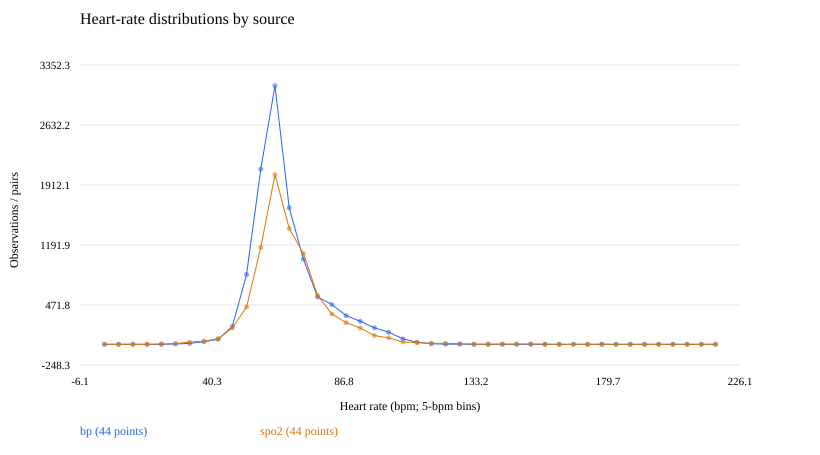

In [9]:
hr_quality_flags = []
for r in hr_observations:
    reasons = []
    present = r['hr_bpm'] is not None
    if present != (r['source'] is not None): reasons.append('hr_source_missingness_mismatch')
    if present:
        if r['patient'] is None: reasons.append('missing_patient')
        if r.get('json_id') is None: reasons.append('missing_json_id')
        if r.get('transm_id') is None: reasons.append('missing_transmission_id')
        if r['time'] is None: reasons.append('missing_or_invalid_time')
        if r['source'] not in HR_SOURCES: reasons.append('unknown_source')
        if r['value'] is None or not math.isfinite(r['value']): reasons.append('nonnumeric_or_nonfinite_hr')
        elif r['value'] <= 0: reasons.append('nonpositive_hr')
        elif not r['value'].is_integer(): reasons.append('fractional_hr_review')
        if r['source']=='bp' and any(r.get(k) is None for k in ('syst_bp_mmhg','diast_bp_mmhg','map_mmhg')):
            reasons.append('missing_bp_companion')
        if r['source']=='spo2' and r.get('spo2_pct') is None: reasons.append('missing_spo2_companion')
        if r['source']=='bp' and r.get('spo2_pct') is not None: reasons.append('unexpected_spo2_companion')
        if r['source']=='spo2' and r.get('syst_bp_mmhg') is not None: reasons.append('unexpected_bp_companion')
    for reason in reasons:
        hr_quality_flags.append(dict(row_id=r['row_id'], patient=r['patient'], source=r['source'], reason=reason))
hr_eligible = [r for r in hr_present if r['patient'] is not None and r['time'] is not None
               and r['source'] in HR_SOURCES and r['value'] is not None and math.isfinite(r['value']) and r['value']>0]
hr_source_summary = []
for source in HR_SOURCES:
    rows = [r for r in hr_eligible if r['source']==source]
    hr_source_summary.append(dict(source=source, reported=sum(r['source']==source for r in hr_present),
        patients=len({r['patient'] for r in rows}), **hr_describe([r['value'] for r in rows])))
hr_table('Source coverage and heart-rate distribution (bpm)', hr_source_summary)
hr_table('Structural quality flags', [dict(reason=k, rows=v) for k,v in Counter(r['reason'] for r in hr_quality_flags).items()])
hr_patient_source_coverage = []
for patient in sorted({r['patient'] for r in hr_eligible}):
    rows = [r for r in hr_eligible if r['patient']==patient]
    hr_patient_source_coverage.append(dict(patient=patient, bp=sum(r['source']=='bp' for r in rows),
        spo2=sum(r['source']=='spo2' for r in rows), first=min(r['time'] for r in rows), last=max(r['time'] for r in rows)))
hr_table('Patient/source coverage', hr_patient_source_coverage)
hr_histogram('Heart-rate distributions by source', [(s,[r['value'] for r in hr_eligible if r['source']==s]) for s in HR_SOURCES],
             list(range(0, 221, 5)), 'Heart rate (bpm; 5-bpm bins)')
hr_text(f'{len(hr_present)-len(hr_eligible)} reported heart rates cannot enter time/value comparisons. '
        'They remain in hr_observations and the audit flags; no rows have been removed from df.')


### 2. Identity, full acquisition payloads, and original timestamp metadata

The provisional event key is `(patient, source, transm_id)`; its true uniqueness
must be confirmed with the data provider. Repetition with an identical retained
payload differs from repetition with changed values. Different IDs with the same
time and HR are only duplicate candidates. Compare all retained companion values.

Where the original JSON files are available, inspect acquisition timestamp syntax,
device/model metadata, units, and registration delays. Matching back to JSON uses
`(json_id, source, transm_id)` and preserves ambiguous matches. A difference between
registration and acquisition is a recorded delay, not a measured clock error.
Original minute-only timestamps cannot establish simultaneity within the minute.


In [10]:
hr_event_groups = defaultdict(list)
hr_exact_groups = defaultdict(list)
for r in hr_present:
    if r['patient'] is not None and r['source'] in HR_SOURCES and r.get('transm_id') is not None:
        hr_event_groups[(r['patient'],r['source'],r['transm_id'])].append(r)
for r in hr_eligible:
    hr_exact_groups[(r['patient'],r['source'],r['time'],r['value'])].append(r)
hr_event_repeats = []
for key, rows in hr_event_groups.items():
    if len(rows)>1:
        payloads = {repr(tuple(r.get(k) for k in hr_payload_fields)) for r in rows}
        hr_event_repeats.append(dict(patient=key[0],source=key[1],transm_id=key[2],rows=len(rows),
            row_ids=tuple(r['row_id'] for r in rows),classification='identical_retained_payload' if len(payloads)==1 else 'changed_payload'))
hr_exact_candidates = []
for key, rows in hr_exact_groups.items():
    if len(rows)>1:
        hr_exact_candidates.append(dict(patient=key[0],source=key[1],time=key[2],hr=key[3],rows=len(rows),
            row_ids=tuple(r['row_id'] for r in rows),transmission_ids=tuple(r['transm_id'] for r in rows),
            companion_payloads_equal=len({repr(tuple(r.get(k) for k in hr_payload_fields)) for r in rows})==1))
hr_table('Repeated provisional event keys', hr_event_repeats)
hr_table('Same-source, same-time, same-HR candidates', hr_exact_candidates, limit=30)
hr_text(f'{len(hr_exact_candidates)} exact measurement candidate groups; '
        f'{sum(r["rows"]-1 for r in hr_exact_candidates)} excess HR entries if one were retained per group. '
        'This is not a recommendation to delete them.')
hr_time_precision = [dict(source=s, rows=sum(r['source']==s for r in hr_eligible),
    nonzero_seconds=sum(r['source']==s and (r['time'].second!=0 or r['time'].microsecond!=0) for r in hr_eligible)) for s in HR_SOURCES]
hr_table('Precision of retained acquisition timestamps', hr_time_precision)

hr_project_root = Path(ff.PROJECT_ROOT) if 'ff' in globals() else (Path.cwd().parent if Path.cwd().name=='analysis' else Path.cwd())
hr_raw_dir = hr_project_root / 'data/1-cleaned_originals/jsons-pp-4'
hr_raw_index = defaultdict(list)
hr_raw_errors = []
hr_type_source = {'BloodPressureTransmission':'bp','SpO2Transmission':'spo2'}
def hr_flatten_instances(value):
    if isinstance(value,list):
        for item in value:
            yield from hr_flatten_instances(item)
    elif isinstance(value,dict):
        yield value

for path in sorted(hr_raw_dir.glob('*.json')):
    try:
        document = json.loads(path.read_text())
        json_id = int(path.name.split('-')[0])
        for transmission_type, source in hr_type_source.items():
            for instance in hr_flatten_instances(document.get('transmissions',{}).get(transmission_type,[])):
                data = instance.get('transmission_data') or {}
                heart = data.get('heartrate') or {}
                stamp = data.get('timestamp')
                hr_raw_index[(json_id,source,str(instance.get('id')))].append(dict(
                    timestamp_text=stamp, acquisition=hr_time(stamp),
                    registration=hr_time(instance.get('registration_time')),
                    created=hr_time(instance.get('created_at')), updated=hr_time(instance.get('updated_at')),
                    device=data.get('device'), serial=data.get('serialnumber') or instance.get('device_sn'),
                    unit=heart.get('unit'), raw_hr=hr_number(heart.get('value'))))
    except (OSError,ValueError,TypeError,AttributeError) as error:
        hr_raw_errors.append(dict(file=path.name,error=str(error)))
hr_metadata = []
for r in hr_eligible:
    matches = (hr_raw_index.get((int(r['json_id']),r['source'],str(r['transm_id'])),[])
               if r.get('json_id') is not None and r.get('transm_id') is not None else [])
    item = dict(row_id=r['row_id'], source=r['source'],raw_matches=len(matches))
    if len(matches)==1:
        item.update(matches[0])
        item['acquisition_matches'] = item['acquisition']==r['time']
        item['hr_matches'] = item['raw_hr']==r['value']
        item['registration_delay_minutes'] = ((item['registration']-item['acquisition']).total_seconds()/60
                                               if item['registration'] and item['acquisition'] else None)
        # Source strings such as 2025-05-13T15:53Z contain no seconds component.
        item['minute_only_text'] = bool(item['timestamp_text'] and len(item['timestamp_text'].split('T')[-1].rstrip('Z').split(':'))==2)
    hr_metadata.append(item)
hr_metadata_by_id = {r['row_id']:r for r in hr_metadata}
hr_metadata_summary = []
for s in HR_SOURCES:
    rows = [r for r in hr_metadata if r['source']==s]
    matched = [r for r in rows if r['raw_matches']==1]
    hr_metadata_summary.append(dict(source=s, rows=len(rows),unique_raw_match=len(matched),
        missing_raw=sum(r['raw_matches']==0 for r in rows),ambiguous_raw=sum(r['raw_matches']>1 for r in rows),
        timestamp_mismatch=sum(not r['acquisition_matches'] for r in matched),
        hr_mismatch=sum(not r['hr_matches'] for r in matched),minute_only_raw=sum(r['minute_only_text'] for r in matched),
        units=dict(Counter(r['unit'] for r in matched)),models=dict(Counter(r['device'] for r in matched)),
        distinct_serials=len({r['serial'] for r in matched if r['serial']})))
hr_table('Original JSON metadata reconciliation', hr_metadata_summary)
hr_table('Raw JSON parse errors (empty is expected)', hr_raw_errors)
hr_table('Registration minus acquisition time (minutes)', [dict(source=s,**hr_describe([
    r.get('registration_delay_minutes') for r in hr_metadata if r['source']==s])) for s in HR_SOURCES])
hr_table('Database creation minus acquisition time (minutes)', [dict(source=s,**hr_describe([
    (r['created']-r['acquisition']).total_seconds()/60
    for r in hr_metadata if r['source']==s and r.get('created') and r.get('acquisition')])) for s in HR_SOURCES])
hr_exact_metadata=[]
for group in hr_exact_candidates:
    for row_id in group['row_ids']:
        r=hr_by_id[row_id]
        m=hr_metadata_by_id.get(row_id,{})
        hr_exact_metadata.append(dict(row_id=row_id,source=r['source'],transm_id=r['transm_id'],
            acquisition=r['time'],hr=r['value'],serial=m.get('serial'),
            registration=m.get('registration'),created=m.get('created'),updated=m.get('updated')))
hr_table('Original metadata for every exact measurement candidate',hr_exact_metadata,limit=30)
hr_text('Original metadata are unavailable for unmatched records; do not interpret a missing JSON match as an invalid measurement. '
        'UTC normalization follows the import pipeline. Clock synchronization cannot be established from these fields alone.')


patient,source,time,hr,rows,row_ids,transmission_ids,companion_payloads_equal
16457305258260151724820,bp,2025-07-09 06:26:00,74,2,"(1672, 1673)","(26391, 26205)",True
35574693925141304521024,spo2,2025-03-02 07:11:00,67,2,"(8786, 8787)","(11270, 11271)",True
37702498860355338996199,bp,2025-11-15 08:05:00,64,2,"(9572, 9573)","(40750, 40753)",True
42756701435568231884338,bp,2025-10-05 08:16:00,70,2,"(11973, 11974)","(37043, 37045)",True
42756701435568231884338,bp,2025-11-03 07:14:00,80,2,"(12026, 12027)","(39687, 39868)",True
48723979829550661294774,bp,2025-03-08 10:31:00,51,2,"(12626, 12627)","(11667, 11668)",True
48808184293616230919996,bp,2024-11-15 08:47:00,60,2,"(13534, 13535)","(11845, 11847)",True
55780508377747749630170,bp,2025-10-24 08:40:00,56,2,"(18022, 18023)","(38699, 38701)",True
61095833656643152147973,bp,2025-07-12 09:35:00,64,2,"(21453, 21454)","(26617, 26618)",True
67144642937947361890761,bp,2025-08-16 07:47:00,53,2,"(24377, 24378)","(30976, 30975)",True


source,rows,nonzero_seconds
bp,11139,0
spo2,8153,0


source,rows,unique_raw_match,missing_raw,ambiguous_raw,timestamp_mismatch,hr_mismatch,minute_only_raw,units,models,distinct_serials
bp,11139,11139,0,0,0,0,11139,{'bpm': 11139},{'Tel-O-Graph': 11139},53
spo2,8153,8153,0,0,0,0,8153,{'bpm': 8153},{'Nonin 3230': 8153},45


source,n,minimum,p01,median,p95,p99,maximum
bp,11139,0,0,0,0,0,0
spo2,8153,0,0,0,0,0,0


source,n,minimum,p01,median,p95,p99,maximum
bp,11139,-59.9,-57.833,-2.933,"27,213.708","181,720.307","4,289,683.133"
spo2,8153,-0.883,1.083,3.083,"18,055.94","31,005.061","29,375,522.4"


row_id,source,transm_id,acquisition,hr,serial,registration,created,updated
1672,bp,26391,2025-07-09 06:26:00,74,TL00092T,2025-07-09 06:26:00,2025-07-11 07:21:06,2025-07-11 07:21:06
1673,bp,26205,2025-07-09 06:26:00,74,TL00092T,2025-07-09 06:26:00,2025-07-10 06:48:04,2025-07-10 06:48:04
8786,spo2,11270,2025-03-02 07:11:00,67,506370466,2025-03-02 07:11:00,2025-03-02 07:12:05,2025-03-02 07:12:05
8787,spo2,11271,2025-03-02 07:11:00,67,506370466,2025-03-02 07:11:00,2025-03-02 07:15:25,2025-03-02 07:15:25
9572,bp,40750,2025-11-15 08:05:00,64,TL000930,2025-11-15 08:05:00,2025-11-15 07:51:07,2025-11-15 07:51:07
9573,bp,40753,2025-11-15 08:05:00,64,TL000930,2025-11-15 08:05:00,2025-11-15 07:54:05,2025-11-15 07:54:05
11973,bp,37043,2025-10-05 08:16:00,70,TL00094C,2025-10-05 08:16:00,2025-10-08 07:54:05,2025-10-08 07:54:05
11974,bp,37045,2025-10-05 08:16:00,70,TL00094C,2025-10-05 08:16:00,2025-10-08 07:57:06,2025-10-08 07:57:06
12026,bp,39687,2025-11-03 07:14:00,80,TL00094C,2025-11-03 07:14:00,2025-11-03 07:03:05,2025-11-03 07:03:05
12027,bp,39868,2025-11-03 07:14:00,80,TL00094C,2025-11-03 07:14:00,2025-11-05 10:12:11,2025-11-05 10:12:11


### 3. Source-aware nearby-pair audit

Enumerate **every unordered pair within five minutes**, separately by patient.
Retain the two row IDs, sources, values, timestamps, event IDs, and full-payload
comparison. Different patients are never compared. Pair classes describe evidence;
they do not trigger cleaning. Equal values at different times are repeat candidates.
Same-time cross-source equality means agreement, not duplication.


In [11]:
hr_patient_rows = defaultdict(list)
hr_patient_source_rows = defaultdict(list)
for r in hr_eligible:
    hr_patient_rows[r['patient']].append(r)
    hr_patient_source_rows[(r['patient'],r['source'])].append(r)
for rows in list(hr_patient_rows.values()) + list(hr_patient_source_rows.values()):
    rows.sort(key=lambda r:(r['time'],r['row_id']))
hr_pairs = []
for patient, rows in hr_patient_rows.items():
    for i,a in enumerate(rows):
        for b in rows[i+1:]:
            minutes = (b['time']-a['time']).total_seconds()/60
            if minutes > max(HR_TIME_WINDOWS): break
            same_source = a['source']==b['source']
            difference = abs(a['value']-b['value'])
            same_event = same_source and a.get('transm_id') is not None and a['transm_id']==b['transm_id']
            same_payload = all(a.get(k)==b.get(k) for k in hr_payload_fields)
            if same_event:
                classification = 'repeated_event_same_payload' if same_payload else 'repeated_event_changed_payload'
            elif same_source and minutes==0 and difference==0:
                classification = 'exact_measurement_candidate'
            elif same_source and minutes==0:
                classification = 'same_source_same_time_different_value'
            elif same_source:
                classification = 'same_source_repeat_candidate'
            else:
                classification = 'cross_source_agreement_candidate' if difference<=5 else 'cross_source_discordance_review'
            signed = ((b['value']-a['value']) if a['source']=='bp' else (a['value']-b['value'])) if not same_source else None
            hr_pairs.append(dict(patient=patient,row_id_1=a['row_id'],row_id_2=b['row_id'],
                source_1=a['source'],source_2=b['source'],comparison='/'.join(sorted([a['source'],b['source']])),
                time_1=a['time'],time_2=b['time'],hr_1=a['value'],hr_2=b['value'],
                transm_id_1=a['transm_id'],transm_id_2=b['transm_id'],json_id_1=a['json_id'],json_id_2=b['json_id'],
                time_minutes=minutes,absolute_difference=difference,spo2_minus_bp=signed,
                same_source=same_source,same_timestamp=minutes==0,same_value=difference==0,
                same_event_key=same_event,same_retained_payload=same_payload,classification=classification))
hr_table('Pair classifications within five minutes', [dict(classification=k,pairs=v) for k,v in Counter(p['classification'] for p in hr_pairs).items()])
hr_table('Same-time pairs', [p for p in hr_pairs if p['time_minutes']==0], limit=15,
    columns=['patient','row_id_1','row_id_2','comparison','hr_1','hr_2','absolute_difference','classification'])
hr_text('The 5-bpm cross-source label is only an initial review setting. All time/value thresholds are evaluated next. '
        'A patient with n nearby readings can contribute n(n−1)/2 pairs; pairs are not independent events.')


classification,pairs
cross_source_discordance_review,512
cross_source_agreement_candidate,1456
same_source_repeat_candidate,3070
exact_measurement_candidate,11
same_source_same_time_different_value,1


patient,row_id_1,row_id_2,comparison,hr_1,hr_2,absolute_difference,classification
10215810359558408931496,15,16,bp/spo2,73,69,4,cross_source_agreement_candidate
10215810359558408931496,34,35,bp/spo2,47,50,3,cross_source_agreement_candidate
10215810359558408931496,49,50,bp/spo2,62,58,4,cross_source_agreement_candidate
10215810359558408931496,58,59,bp/spo2,49,48,1,cross_source_agreement_candidate
10215810359558408931496,71,72,bp/spo2,50,50,0,cross_source_agreement_candidate
10215810359558408931496,75,76,bp/spo2,52,51,1,cross_source_agreement_candidate
10215810359558408931496,90,91,bp/spo2,62,48,14,cross_source_discordance_review
10215810359558408931496,93,94,bp/spo2,61,60,1,cross_source_agreement_candidate
10215810359558408931496,100,101,bp/spo2,51,53,2,cross_source_agreement_candidate
10215810359558408931496,107,108,bp/spo2,52,49,3,cross_source_agreement_candidate


### 4. Threshold sensitivity, patient concentration, and repeat patterns

Cross time windows (0, 1, 2, 5 minutes) with value tolerances (0, 3, 5, 10 bpm).
Report pairs **and distinct observations and patients**, including patients affected
by discordance. The windows are cumulative. Thresholds identify review candidates,
not invalid records. Consecutive same-source gaps reveal acquisition bursts without
confusing their numerous overlapping pairs with numerous independent episodes.


minutes,comparison,pairs,observations,patients,equal,median_difference,p95_difference,maximum
0,bp/bp,10,20,9,9,0,1.65,3
0,spo2/spo2,2,4,2,2,0,0,0
0,bp/spo2,203,406,18,26,3,12.9,19
1,bp/bp,896,1535,37,131,2,11,32
1,spo2/spo2,92,184,31,10,4.5,20.45,72
1,bp/spo2,595,1176,25,56,3,13,35
2,bp/bp,1884,2760,46,246,2,11,32
2,spo2/spo2,190,366,39,28,5,22,72
2,bp/spo2,1039,2043,29,127,3,14,80
5,bp/bp,2786,3653,46,369,2,11,38


minutes,comparison,tolerance_bpm,pairs,within_tolerance,discordant_pairs,discordant_percent,affected_observations,affected_patients
0,bp/bp,0,10,9,1,10,2,1
0,bp/bp,3,10,10,0,0,0,0
0,bp/bp,5,10,10,0,0,0,0
0,bp/bp,10,10,10,0,0,0,0
0,spo2/spo2,0,2,2,0,0,0,0
0,spo2/spo2,3,2,2,0,0,0,0
0,spo2/spo2,5,2,2,0,0,0,0
0,spo2/spo2,10,2,2,0,0,0,0
0,bp/spo2,0,203,26,177,87.192,354,16
0,bp/spo2,3,203,110,93,45.813,186,10


patient,pairs,discordant_gt10,involved_observations
1685041082445787054942,968,85,950
48808184293616230919996,407,61,525
52732966867258486633869,453,38,885
44761223044751751230474,262,22,311
30558454646602157096476,150,21,291
4993743863956065795610,157,18,271
60273396536601177272560,188,15,239
56588991354167876598234,34,12,62
72323953519329744347208,329,12,422
31641425359519401288731,137,11,254


source,n,minimum,p01,median,p95,p99,maximum
bp,11086,0,1,"1,414","2,861","7,167.15","4,290,098"
spo2,8101,0,1,"1,437","2,983","11,093","29,279,079"


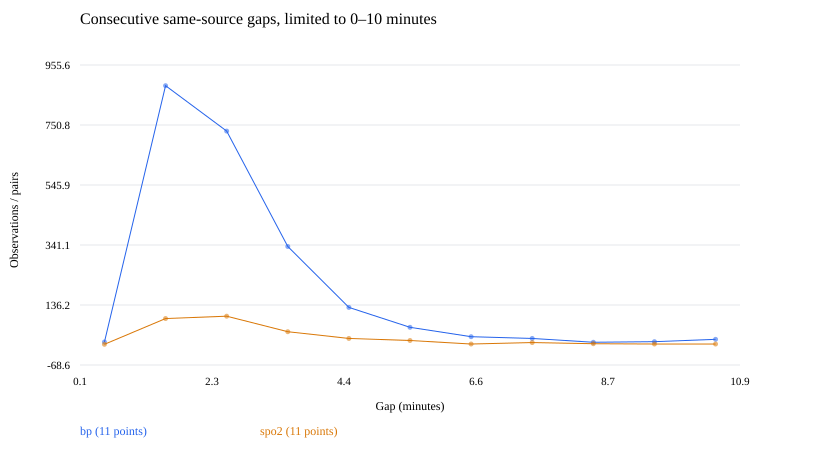

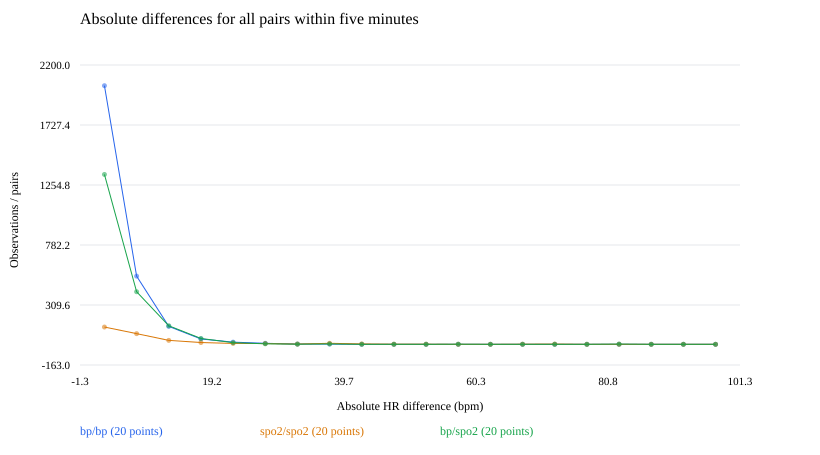

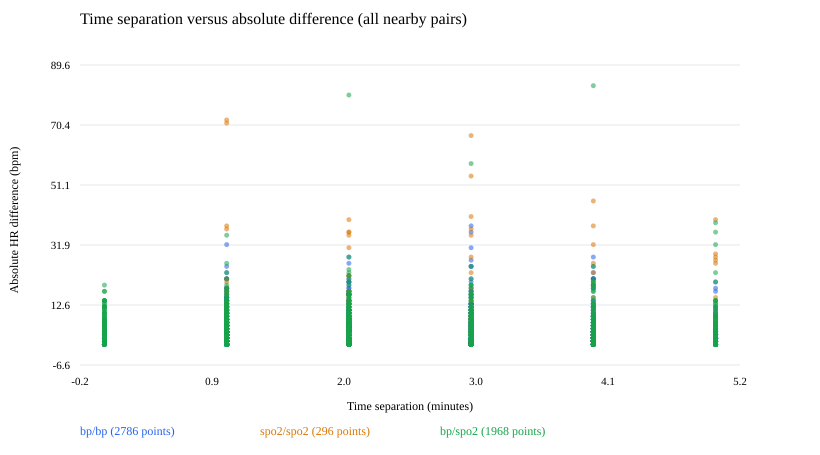

In [12]:
hr_sensitivity = []
hr_window_summary = []
for minutes in HR_TIME_WINDOWS:
    for comparison in ('bp/bp','spo2/spo2','bp/spo2'):
        selected = [p for p in hr_pairs if p['comparison']==comparison and p['time_minutes']<=minutes]
        ids = {p[k] for p in selected for k in ('row_id_1','row_id_2')}
        differences = [p['absolute_difference'] for p in selected]
        hr_window_summary.append(dict(minutes=minutes,comparison=comparison,pairs=len(selected),
            observations=len(ids),patients=len({p['patient'] for p in selected}),equal=sum(d==0 for d in differences),
            median_difference=hr_q(differences,.5),p95_difference=hr_q(differences,.95),maximum=max(differences,default=None)))
        for tolerance in HR_VALUE_LIMITS:
            discordant = [p for p in selected if p['absolute_difference']>tolerance]
            hr_sensitivity.append(dict(minutes=minutes,comparison=comparison,tolerance_bpm=tolerance,
                pairs=len(selected),within_tolerance=len(selected)-len(discordant),discordant_pairs=len(discordant),
                discordant_percent=100*len(discordant)/len(selected) if selected else None,
                affected_observations=len({p[k] for p in discordant for k in ('row_id_1','row_id_2')}),
                affected_patients=len({p['patient'] for p in discordant})))
hr_table('Time-window summaries', hr_window_summary, limit=20)
hr_table('Full threshold sensitivity grid', hr_sensitivity, limit=48)
hr_patient_pair_summary = []
for patient in hr_patient_rows:
    selected = [p for p in hr_pairs if p['patient']==patient]
    hr_patient_pair_summary.append(dict(patient=patient,pairs=len(selected),
        discordant_gt10=sum(p['absolute_difference']>10 for p in selected),
        involved_observations=len({p[k] for p in selected for k in ('row_id_1','row_id_2')})))
hr_patient_pair_summary.sort(key=lambda r:r['discordant_gt10'],reverse=True)
hr_table('Patients contributing most >10-bpm discordant pairs (five-minute window)', hr_patient_pair_summary)
hr_consecutive = []
for (patient,source),rows in hr_patient_source_rows.items():
    for a,b in zip(rows,rows[1:]):
        gap = (b['time']-a['time']).total_seconds()/60
        hr_consecutive.append(dict(patient=patient,source=source,row_id_1=a['row_id'],row_id_2=b['row_id'],
            gap_minutes=gap,absolute_difference=abs(b['value']-a['value']),
            change_per_minute=(b['value']-a['value'])/gap if gap>0 else None))
hr_table('Consecutive same-source gap summaries (all gaps, minutes)', [dict(source=s,
    **hr_describe([r['gap_minutes'] for r in hr_consecutive if r['source']==s])) for s in HR_SOURCES])
hr_histogram('Consecutive same-source gaps, limited to 0–10 minutes',
    [(s,[r['gap_minutes'] for r in hr_consecutive if r['source']==s]) for s in HR_SOURCES],list(range(12)), 'Gap (minutes)')
hr_histogram('Absolute differences for all pairs within five minutes',
    [(s,[p['absolute_difference'] for p in hr_pairs if p['comparison']==s]) for s in ('bp/bp','spo2/spo2','bp/spo2')],
    list(range(0,101,5)), 'Absolute HR difference (bpm)')
hr_plot('Time separation versus absolute difference (all nearby pairs)',
    [(s,[(p['time_minutes'],p['absolute_difference']) for p in hr_pairs if p['comparison']==s])
     for s in ('bp/bp','spo2/spo2','bp/spo2')], 'Time separation (minutes)', 'Absolute HR difference (bpm)')


### 5. Agreement between sources with time-only matching

The all-pair audit above is deliberately exhaustive. For method comparison, make
**one-to-one pairs using time only**, separately within each patient. A deterministic
greedy rule accepts the smallest time gaps first, breaking ties by row ID. It is not
a global maximum-cardinality/optimal assignment; ambiguous candidate counts and tie
counts are reported, and different windows provide a sensitivity analysis. No value
similarity enters matching. Repeated event keys are reduced to one representative
only when their retained payloads agree; changed-payload keys are excluded from
agreement estimation and remain in the audit. Distinct transmission IDs are retained.

Positive signed differences mean SpO₂-device HR exceeds BP-device HR. Report bias,
median absolute difference, tail differences, and approximate Bland–Altman limits
of agreement (bias ± 1.96 SD). Those limits describe observed differences; they are
**not clinical acceptance limits**. Histograms and plots check long tails and
dependence on measurement magnitude or time separation. Correlation is not a test
of interchangeability. See [Bland & Altman (1986)](https://www-users.york.ac.uk/~mb55/meas/ba.htm).

Patient-cluster bootstrap intervals resample whole patients, retaining dependence
among their matched readings. They quantify uncertainty in the pooled-pair bias;
an equal-patient-weight estimate is also shown. Neither source is a gold standard,
and patient state, source selection, timing, and device effects remain confounded.


window_minutes,pairs,patients,bias_spo2_minus_bp,median_absolute_difference,p95_absolute_difference,sd_difference,loa_lower,loa_upper,within5_percent,within10_percent,ambiguous_matches,matches_with_time_ties
0,203,18,1.31,3,12.9,5.794,-10.046,12.667,69.951,89.163,0,0
1,582,25,1.363,4,13,6.32,-11.025,13.75,65.636,89.175,14,4
2,1006,29,1.169,3,14,6.824,-12.207,14.545,67.396,89.264,30,6
5,1724,33,1.002,2,13,6.513,-11.763,13.767,74.768,91.531,231,7


pairs,patients,bias_spo2_minus_bp,median_absolute_difference,p95_absolute_difference,sd_difference,loa_lower,loa_upper,within5_percent,within10_percent,ambiguous_matches,matches_with_time_ties
976,29,1.19,3,14,6.907,-12.348,14.727,66.598,88.934,0,0


n,minimum,p01,median,p95,p99,maximum,spo2_before_bp,same_recorded_minute,spo2_after_bp
1006,-2,-2,0,2,2,2,423,203,380


patient,pairs,patients,bias_spo2_minus_bp,median_absolute_difference,p95_absolute_difference,sd_difference,loa_lower,loa_upper,within5_percent,within10_percent,ambiguous_matches,matches_with_time_ties
10215810359558408931496,100,1,-1.23,2,10.05,4.69,-10.423,7.963,80,95,3,1
16457305258260151724820,1,1,-2,2,2,—,—,—,100,100,0,0
1685041082445787054942,3,1,1.667,0,4.5,2.887,-3.991,7.325,100,100,2,0
21641783462018789544099,3,1,5.333,3,9.3,4.041,-2.588,13.255,66.667,100,0,0
24237081325524430327506,1,1,-5,5,5,—,—,—,100,100,0,0
25091128815292953435003,24,1,-0.667,1,6,2.884,-6.32,4.986,87.5,100,4,1
2754773772226996038047,1,1,10,10,10,—,—,—,0,100,0,0
30558454646602157096476,103,1,5.35,6,13,4.226,-2.933,13.632,49.515,89.32,1,0
30643187258202083689918,1,1,-22,22,22,—,—,—,0,0,0,0
31641425359519401288731,84,1,2.464,3,12.85,5.702,-8.712,13.641,78.571,90.476,3,1


statistic,lower,upper,replicates
bias,-0.205,2.534,400
loa_lower,-14.65,-9.59,400
loa_upper,11.638,17.436,400


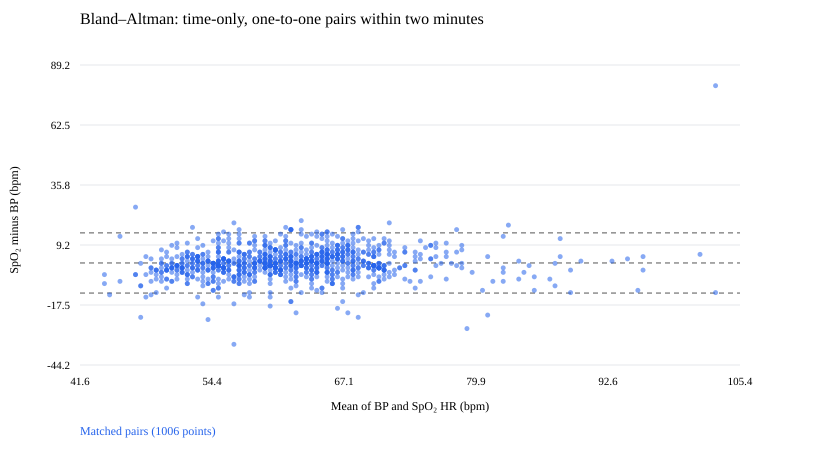

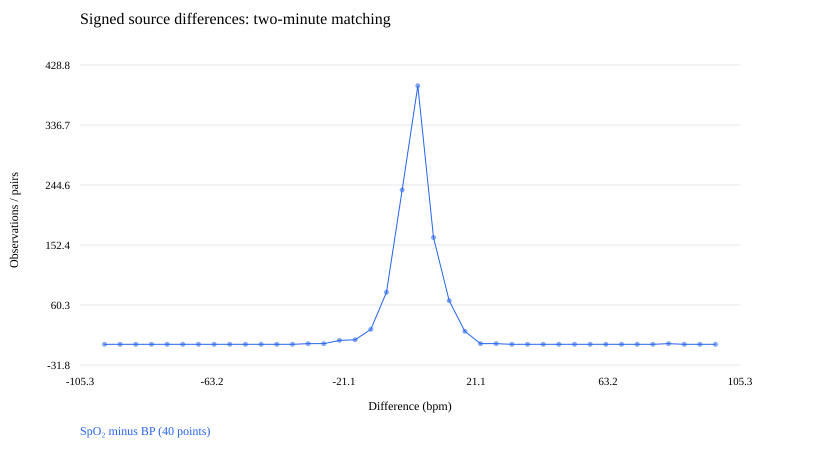

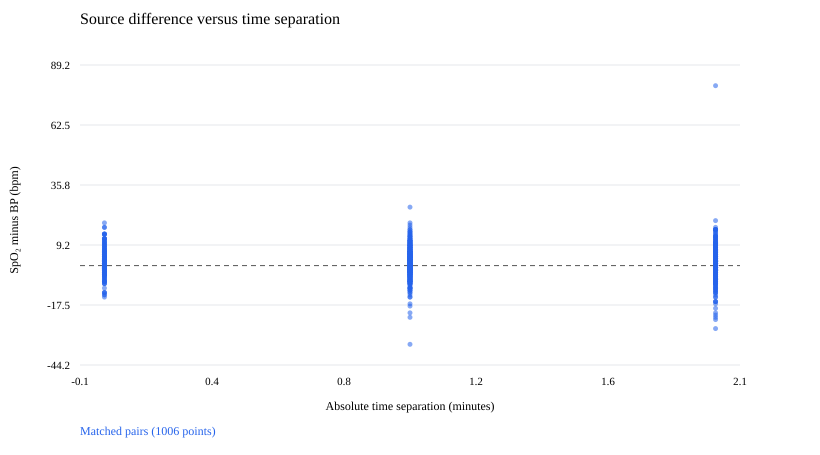

stratum,pairs,patients,bias_spo2_minus_bp,median_absolute_difference,p95_absolute_difference,sd_difference,loa_lower,loa_upper,within5_percent,within10_percent,ambiguous_matches,matches_with_time_ties
mean HR <60,412,16,0.172,3,13,6.138,-11.857,12.202,71.359,90.777,9,1
mean HR 60–89,585,25,1.768,4,14,6.428,-10.831,14.366,64.615,88.547,20,5
mean HR ≥90,9,6,7.889,4,52.8,27.764,-46.529,62.307,66.667,66.667,1,0


bp_model,spo2_model,pairs,patients,bias_spo2_minus_bp,median_absolute_difference,p95_absolute_difference,sd_difference,loa_lower,loa_upper,within5_percent,within10_percent,ambiguous_matches,matches_with_time_ties
Tel-O-Graph,Nonin 3230,1006,29,1.169,3,14,6.824,-12.207,14.545,67.396,89.264,30,6


bp_serial,spo2_serial,pairs,patients,bias_spo2_minus_bp,median_absolute_difference,p95_absolute_difference,sd_difference,loa_lower,loa_upper,within5_percent,within10_percent,ambiguous_matches,matches_with_time_ties
TL0008TE,506387525,225,2,1.404,4,13.6,6.013,-10.382,13.191,66.222,91.111,8,2
TL0008TM,506385541,218,1,-0.046,2,16,6.812,-13.397,13.306,74.312,87.615,2,0
TL00094F,502770055,156,1,1.026,5.5,14.5,7.712,-14.089,16.141,50,82.051,1,0
TL000942,506385484,103,1,5.35,6,13,4.226,-2.933,13.632,49.515,89.32,1,0
TL00093X,506370467,84,1,2.464,3,12.85,5.702,-8.712,13.641,78.571,90.476,3,1
TL00094G,502770014,82,1,-1.061,3.5,10.95,5.227,-11.305,9.183,70.732,93.902,3,2
TL000943,506387519,38,2,0.026,1,3.3,1.533,-2.979,3.031,100,100,2,0
TL0008TG,506387522,32,1,-1.781,3,12,5.517,-12.594,9.032,71.875,84.375,1,0
TL00094K,502770007,24,1,-0.667,1,6,2.884,-6.32,4.986,87.5,100,4,1
TL000935,506385544,7,1,11.857,2,58.7,30.328,-47.586,71.301,71.429,85.714,0,0


month,pairs,patients,bias_spo2_minus_bp,median_absolute_difference,p95_absolute_difference,sd_difference,loa_lower,loa_upper,within5_percent,within10_percent,ambiguous_matches,matches_with_time_ties
2025-01,5,2,-1.4,1,4.8,2.881,-7.047,4.247,100,100,1,0
2025-02,85,5,0.376,4,13,8.015,-15.333,16.086,58.824,85.882,2,1
2025-03,152,10,1.237,3,11.45,8.203,-14.84,17.314,78.289,94.079,5,1
2025-04,101,9,-0.584,2,14,6.017,-12.378,11.209,77.228,92.079,1,0
2025-05,138,9,0.609,2.5,16,6.241,-11.624,12.842,68.841,88.406,7,1
2025-06,117,11,1.462,3,14,6.141,-10.576,13.499,69.231,88.889,3,1
2025-07,102,11,1.422,3,11.95,5.898,-10.138,12.981,71.569,91.176,5,1
2025-08,62,11,2.419,4,13.95,6.099,-9.535,14.373,61.29,88.71,3,1
2025-09,72,7,2.528,5,11.45,5.848,-8.934,13.989,58.333,91.667,3,0
2025-10,52,6,2.288,4,13.45,6.313,-10.085,14.662,59.615,88.462,0,0


In [13]:
hr_agreement_allowed_ids = {r['row_id'] for r in hr_eligible}
for rows in hr_event_groups.values():
    if len(rows)>1:
        same = len({repr(tuple(r.get(k) for k in hr_payload_fields)) for r in rows})==1
        hr_agreement_allowed_ids.difference_update(r['row_id'] for r in rows)
        if same: hr_agreement_allowed_ids.add(rows[0]['row_id'])

def hr_match_pairs(window):
    candidates = [p for p in hr_pairs if not p['same_source'] and p['time_minutes']<=window
                  and p['row_id_1'] in hr_agreement_allowed_ids and p['row_id_2'] in hr_agreement_allowed_ids]
    candidate_counts = Counter(p[k] for p in candidates for k in ('row_id_1','row_id_2'))
    minimum_gaps = {}
    for p in candidates:
        for key in ('row_id_1','row_id_2'):
            row_id=p[key]
            minimum_gaps[row_id]=min(minimum_gaps.get(row_id,float('inf')),p['time_minutes'])
    tie_counts = Counter(p[k] for p in candidates for k in ('row_id_1','row_id_2')
                        if p['time_minutes']==minimum_gaps[p[k]])
    selected, used = [],set()
    for p in sorted(candidates,key=lambda p:(p['time_minutes'],p['row_id_1'],p['row_id_2'])):
        a,b=p['row_id_1'],p['row_id_2']
        if a not in used and b not in used:
            selected.append(dict(p,ambiguous_candidates=candidate_counts[a]>1 or candidate_counts[b]>1,
                                 nearest_time_tie=tie_counts[a]>1 or tie_counts[b]>1))
            used.update((a,b))
    return selected

def hr_agreement_stats(pairs):
    differences=[p['spo2_minus_bp'] for p in pairs]
    absolute=[abs(d) for d in differences]
    bias=statistics.mean(differences) if differences else None
    sd=statistics.stdev(differences) if len(differences)>1 else None
    return dict(pairs=len(pairs),patients=len({p['patient'] for p in pairs}),bias_spo2_minus_bp=bias,
        median_absolute_difference=hr_q(absolute,.5),p95_absolute_difference=hr_q(absolute,.95),
        sd_difference=sd,loa_lower=bias-1.96*sd if sd is not None else None,
        loa_upper=bias+1.96*sd if sd is not None else None,
        within5_percent=100*sum(d<=5 for d in absolute)/len(absolute) if absolute else None,
        within10_percent=100*sum(d<=10 for d in absolute)/len(absolute) if absolute else None,
        ambiguous_matches=sum(p.get('ambiguous_candidates',False) for p in pairs),
        matches_with_time_ties=sum(p.get('nearest_time_tie',False) for p in pairs))

hr_matched_by_window = {window:hr_match_pairs(window) for window in HR_TIME_WINDOWS}
hr_agreement_summary = [dict(window_minutes=w,**hr_agreement_stats(pairs)) for w,pairs in hr_matched_by_window.items()]
hr_table('One-to-one source agreement by time window', hr_agreement_summary)
hr_matches = hr_matched_by_window[2]
hr_table('Matching sensitivity: unambiguous two-minute pairs only',
         [hr_agreement_stats([p for p in hr_matches if not p['ambiguous_candidates']])])
hr_signed_lags=[]
for p in hr_matches:
    a,b=hr_by_id[p['row_id_1']],hr_by_id[p['row_id_2']]
    bp,sp=(a,b) if a['source']=='bp' else (b,a)
    hr_signed_lags.append((sp['time']-bp['time']).total_seconds()/60)
hr_table('Measurement order: SpO₂ time minus BP time (minutes)',[dict(
    **hr_describe(hr_signed_lags),spo2_before_bp=sum(v<0 for v in hr_signed_lags),
    same_recorded_minute=sum(v==0 for v in hr_signed_lags),spo2_after_bp=sum(v>0 for v in hr_signed_lags))])
hr_text('The signed lag describes workflow/order among selected nearby pairs, not clock calibration. '
        'A larger matching window may admit a different patient/measurement population; '
        'changes in agreement across windows cannot be attributed to time separation alone.')
hr_agreement_by_patient = []
for patient in sorted({p['patient'] for p in hr_matches}):
    hr_agreement_by_patient.append(dict(patient=patient,**hr_agreement_stats([p for p in hr_matches if p['patient']==patient])))
hr_table('Per-patient agreement: two-minute matching', hr_agreement_by_patient)
hr_text('Equal-patient-weight mean signed difference (two-minute matching): ' +
        hr_fmt(statistics.mean(r['bias_spo2_minus_bp'] for r in hr_agreement_by_patient) if hr_agreement_by_patient else None) + ' bpm.')

hr_bootstrap = []
hr_cluster_values = defaultdict(list)
for p in hr_matches: hr_cluster_values[p['patient']].append(p['spo2_minus_bp'])
hr_cluster_names = sorted(hr_cluster_values)
hr_rng = random.Random(HR_SEED)
if len(hr_cluster_names)>=2:
    for _ in range(HR_BOOTSTRAPS):
        sampled = hr_rng.choices(hr_cluster_names,k=len(hr_cluster_names))
        differences=[d for patient in sampled for d in hr_cluster_values[patient]]
        bias=statistics.mean(differences)
        sd=statistics.stdev(differences) if len(differences)>1 else 0
        hr_bootstrap.append(dict(bias=bias,loa_lower=bias-1.96*sd,loa_upper=bias+1.96*sd))
hr_table('Patient-cluster bootstrap: 95% percentile intervals, two-minute matching', [
    dict(statistic=k,lower=hr_q([r[k] for r in hr_bootstrap],.025),upper=hr_q([r[k] for r in hr_bootstrap],.975),
         replicates=len(hr_bootstrap)) for k in ('bias','loa_lower','loa_upper')])
hr_primary_stats=hr_agreement_stats(hr_matches)
hr_loa_lines=[hr_primary_stats[k] for k in ('bias_spo2_minus_bp','loa_lower','loa_upper') if hr_primary_stats[k] is not None]
hr_plot('Bland–Altman: time-only, one-to-one pairs within two minutes',
    [('Matched pairs',[((p['hr_1']+p['hr_2'])/2,p['spo2_minus_bp']) for p in hr_matches])],
    'Mean of BP and SpO₂ HR (bpm)','SpO₂ minus BP (bpm)',lines=hr_loa_lines)
hr_histogram('Signed source differences: two-minute matching',
    [('SpO₂ minus BP',[p['spo2_minus_bp'] for p in hr_matches])],list(range(-100,105,5)), 'Difference (bpm)')
hr_plot('Source difference versus time separation',
    [('Matched pairs',[(p['time_minutes'],p['spo2_minus_bp']) for p in hr_matches])],
    'Absolute time separation (minutes)','SpO₂ minus BP (bpm)',lines=[0])
hr_agreement_strata=[]
for label,low,high in [('mean HR <60',0,60),('mean HR 60–89',60,90),('mean HR ≥90',90,float('inf'))]:
    hr_agreement_strata.append(dict(stratum=label,**hr_agreement_stats([
        p for p in hr_matches if low <= (p['hr_1']+p['hr_2'])/2 < high])))
hr_table('Agreement by mean heart-rate range (descriptive, small strata may be unstable)',hr_agreement_strata)
hr_device_agreement_groups=defaultdict(list)
for p in hr_matches:
    a,b=hr_by_id[p['row_id_1']],hr_by_id[p['row_id_2']]
    bp,sp=(a,b) if a['source']=='bp' else (b,a)
    key=(hr_metadata_by_id.get(bp['row_id'],{}).get('device','unknown'),
         hr_metadata_by_id.get(sp['row_id'],{}).get('device','unknown'))
    hr_device_agreement_groups[key].append(p)
hr_table('Agreement by device-model combination', [dict(bp_model=k[0],spo2_model=k[1],**hr_agreement_stats(v))
    for k,v in hr_device_agreement_groups.items()])
hr_serial_agreement_groups=defaultdict(list)
hr_month_agreement_groups=defaultdict(list)
for p in hr_matches:
    a,b=hr_by_id[p['row_id_1']],hr_by_id[p['row_id_2']]
    bp,sp=(a,b) if a['source']=='bp' else (b,a)
    key=(hr_metadata_by_id.get(bp['row_id'],{}).get('serial'),
         hr_metadata_by_id.get(sp['row_id'],{}).get('serial'))
    hr_serial_agreement_groups[key].append(p)
    hr_month_agreement_groups[p['time_1'].strftime('%Y-%m')].append(p)
hr_table('Agreement by device serial combination (patient/device effects may overlap)',
    sorted([dict(bp_serial=k[0],spo2_serial=k[1],**hr_agreement_stats(v))
            for k,v in hr_serial_agreement_groups.items()],key=lambda r:r['pairs'],reverse=True))
hr_table('Agreement by calendar month', [dict(month=k,**hr_agreement_stats(v))
    for k,v in sorted(hr_month_agreement_groups.items())])
hr_text('Inspect tails and sample sizes before interpreting approximate limits of agreement. '
        'Bootstrap intervals do not correct matching bias, rounded timestamps, or device/patient confounding. '
        'These observational pairs cannot establish interchangeability or which source is more accurate.')


### 6. Episodes: fixed bins, gap chaining, and maximum span

Compare three five-minute policies, **within patient and source**:

* Fixed UTC bins: reproducible but split acquisitions across bin boundaries.
* Gap chaining: each consecutive gap is at most five minutes; the total episode
  may be much longer. This is the connected-component interpretation of nearby pairs.
* Maximum span: every observation is within five minutes of the episode's first
  observation. This bounds duration without chaining.

Episode summaries retain member IDs, acquisition count, median, range, and span.
They are candidate derived representations, not changes to the observations.
Source mixing is intentionally deferred until agreement and intended use justify it.


In [14]:
def hr_make_episodes(policy, minutes=5):
    episodes=[]
    epoch=datetime(1970,1,1)
    for (patient,source),rows in hr_patient_source_rows.items():
        groups=[]
        for r in rows:
            new = not groups
            if groups:
                if policy=='fixed_bin':
                    new=int((r['time']-epoch).total_seconds()//(minutes*60)) != int((groups[-1][0]['time']-epoch).total_seconds()//(minutes*60))
                elif policy=='gap_chain':
                    new=(r['time']-groups[-1][-1]['time']).total_seconds()>minutes*60
                elif policy=='maximum_span':
                    new=(r['time']-groups[-1][0]['time']).total_seconds()>minutes*60
                else: raise ValueError(policy)
            if new:groups.append([])
            groups[-1].append(r)
        for group in groups:
            values=[r['value'] for r in group]
            episodes.append(dict(policy=policy,patient=patient,source=source,start=group[0]['time'],end=group[-1]['time'],
                span_minutes=(group[-1]['time']-group[0]['time']).total_seconds()/60,n=len(group),
                hr_median=statistics.median(values),hr_min=min(values),hr_max=max(values),hr_range=max(values)-min(values),
                row_ids=tuple(r['row_id'] for r in group)))
    return episodes
hr_episodes_by_policy={p:hr_make_episodes(p,HR_EPISODE_MINUTES) for p in ('fixed_bin','gap_chain','maximum_span')}
hr_episode_summary=[]
for policy,episodes in hr_episodes_by_policy.items():
    for s in HR_SOURCES:
        rows=[r for r in episodes if r['source']==s]
        hr_episode_summary.append(dict(policy=policy,source=s,episodes=len(rows),
            multi_reading_episodes=sum(r['n']>1 for r in rows),observations=sum(r['n'] for r in rows),
            longest_span_minutes=max((r['span_minutes'] for r in rows),default=None),
            spans_over5=sum(r['span_minutes']>5 for r in rows),range_over10=sum(r['hr_range']>10 for r in rows)))
hr_table('Five-minute grouping-policy comparison',hr_episode_summary)
hr_table('Gap-chain episodes exceeding the intended five-minute span',
    sorted([r for r in hr_episodes_by_policy['gap_chain'] if r['span_minutes']>5],key=lambda r:r['span_minutes'],reverse=True))
hr_candidate_episodes=hr_episodes_by_policy['maximum_span']
hr_table('Maximum-span episodes with largest within-episode differences',
    sorted([r for r in hr_candidate_episodes if r['n']>1],key=lambda r:r['hr_range'],reverse=True))
hr_text('A median summarizes a group but does not resolve disagreement. For two readings it equals their average. '
        'Group membership must be determined using only data available by the prediction time.')


policy,source,episodes,multi_reading_episodes,observations,longest_span_minutes,spans_over5,range_over10
fixed_bin,bp,9820,1092,11139,4,0,83
fixed_bin,spo2,8012,133,8153,4,0,29
gap_chain,bp,8990,1504,11139,16,57,133
gap_chain,spo2,7881,244,8153,10,7,59
maximum_span,bp,9052,1528,11139,5,0,128
maximum_span,spo2,7888,244,8153,5,0,57


policy,patient,source,start,end,span_minutes,n,hr_median,hr_min,hr_max,hr_range,row_ids
gap_chain,67144642937947361890761,bp,2025-07-29 17:19:00,2025-07-29 17:35:00,16,7,65,63,71,8,"(24320, 24321, 24322, 24323, 24326, 24327, 24328)"
gap_chain,67144642937947361890761,bp,2025-08-16 07:41:00,2025-08-16 07:57:00,16,10,53,51,54,3,"(24374, 24375, 24376, 24377, 24378, 24380, 24381, 24382, 24383, 24384)"
gap_chain,67144642937947361890761,bp,2025-09-18 11:41:00,2025-09-18 11:56:00,15,6,67,64,70,6,"(24522, 24523, 24524, 24525, 24526, 24527)"
gap_chain,67144642937947361890761,bp,2025-09-17 16:48:00,2025-09-17 17:02:00,14,7,59,55,61,6,"(24510, 24511, 24512, 24513, 24514, 24515, 24516)"
gap_chain,67144642937947361890761,bp,2025-09-02 17:18:00,2025-09-02 17:31:00,13,6,57,57,59,2,"(24443, 24444, 24445, 24446, 24447, 24448)"
gap_chain,44761223044751751230474,bp,2025-06-20 06:07:00,2025-06-20 06:19:00,12,5,52,50,58,8,"(12424, 12425, 12426, 12427, 12428)"
gap_chain,67144642937947361890761,bp,2025-09-07 17:14:00,2025-09-07 17:26:00,12,5,68,66,71,5,"(24470, 24471, 24472, 24473, 24474)"
gap_chain,16457305258260151724820,bp,2025-09-26 05:07:00,2025-09-26 05:18:00,11,5,71,70,72,2,"(1787, 1788, 1789, 1790, 1791)"
gap_chain,11063043325284003255284,bp,2025-09-04 05:41:00,2025-09-04 05:51:00,10,3,60,58,60,2,"(881, 882, 883)"
gap_chain,37179856670640465077171,bp,2025-05-13 04:54:00,2025-05-13 05:04:00,10,3,73,72,79,7,"(9351, 9352, 9353)"


policy,patient,source,start,end,span_minutes,n,hr_median,hr_min,hr_max,hr_range,row_ids
maximum_span,56588991354167876598234,spo2,2025-03-30 09:56:00,2025-03-30 09:59:00,3,3,109,74,146,72,"(18347, 18348, 18349)"
maximum_span,6679885642792556738696,spo2,2025-06-06 05:44:00,2025-06-06 05:45:00,1,2,84.5,49,120,71,"(24025, 24026)"
maximum_span,6679885642792556738696,spo2,2025-05-30 05:56:00,2025-05-30 05:59:00,3,2,86.5,53,120,67,"(24003, 24004)"
maximum_span,58665277459085166003571,spo2,2025-04-26 04:44:00,2025-04-26 04:47:00,3,2,85,58,112,54,"(20469, 20470)"
maximum_span,44761223044751751230474,spo2,2025-06-04 06:06:00,2025-06-04 06:10:00,4,2,82,59,105,46,"(12383, 12384)"
maximum_span,58665277459085166003571,spo2,2025-04-26 06:50:00,2025-04-26 06:54:00,4,3,65,42,83,41,"(20472, 20473, 20474)"
maximum_span,5712560221500663468891,spo2,2025-03-03 06:00:00,2025-03-03 06:02:00,2,2,81,61,101,40,"(19365, 19366)"
maximum_span,44761223044751751230474,spo2,2025-03-18 07:34:00,2025-03-18 07:35:00,1,2,81,62,100,38,"(12133, 12134)"
maximum_span,5443382870799330932690,spo2,2025-07-14 05:46:00,2025-07-14 05:50:00,4,2,78,59,97,38,"(17339, 17340)"
maximum_span,5712560221500663468891,spo2,2025-03-05 05:28:00,2025-03-05 05:29:00,1,2,78.5,60,97,37,"(19372, 19373)"


### 7. Review queue, unusual values, local context, and proposed actions

Combine structural flags, exact duplicate candidates, >10-bpm discordance within
two minutes, and two descriptive outlier screens: values outside 40–130 bpm and
absolute deviation >5 scaled MAD from the source median. These screens deliberately
do not establish medical invalidity. Global MAD statistics are descriptive audit
outputs and must not be fitted on future validation/test data for model preprocessing.

For every flagged observation retain the preceding/following same-source readings,
time gaps, original event identifiers, and raw device metadata. Review the largest
disagreements with local timelines; also inspect a reproducible random sample of
apparently consistent pairs to avoid reviewing only failures. Proposed actions are
recommendations requiring evidence, not automatic deletion or correction.


source,median,mad,scaled_mad
bp,63,6,8.896
spo2,65,6,8.896


reason,observations
nearby_difference_gt10_within2min,481
outside_exploratory_40_130,139
source_deviation_gt5_scaled_MAD,117
exact_measurement_candidate,22


row_id,patient,source,time,hr,json_id,transm_id,reasons,proposed_action,device,serial,previous_hr,previous_gap_minutes,next_hr,next_gap_minutes
6,10215810359558408931496,spo2,2025-02-11 14:01:00,37,31801,10039,"('outside_exploratory_40_130',)",Retain and flag pending review; do not average discordant values,Nonin 3230,506387525,50,"1,301",56,"1,025"
28,10215810359558408931496,spo2,2025-02-18 07:27:00,52,31801,10401,"('nearby_difference_gt10_within2min',)",Retain and flag pending review; do not average discordant values,Nonin 3230,506387525,49,"1,433",48,"1,426"
29,10215810359558408931496,bp,2025-02-18 07:28:00,73,31801,10402,"('nearby_difference_gt10_within2min',)",Retain and flag pending review; do not average discordant values,Tel-O-Graph,TL0008TE,55,"1,432",50,"1,426"
37,10215810359558408931496,spo2,2025-02-21 07:23:00,64,31801,10612,"('nearby_difference_gt10_within2min',)",Retain and flag pending review; do not average discordant values,Nonin 3230,506387525,50,"1,407",50,"1,462"
38,10215810359558408931496,bp,2025-02-21 07:25:00,53,31801,10617,"('nearby_difference_gt10_within2min',)",Retain and flag pending review; do not average discordant values,Tel-O-Graph,TL0008TE,47,"1,409",51,"1,461"
90,10215810359558408931496,bp,2025-03-10 07:44:00,62,31801,11789,"('nearby_difference_gt10_within2min',)",Retain and flag pending review; do not average discordant values,Tel-O-Graph,TL0008TE,57,"1,421",61,"1,387"
91,10215810359558408931496,spo2,2025-03-10 07:44:00,48,31801,11786,"('nearby_difference_gt10_within2min',)",Retain and flag pending review; do not average discordant values,Nonin 3230,506387525,51,"1,422",60,"1,387"
241,10215810359558408931496,bp,2025-04-28 06:16:00,51,31801,16886,"('nearby_difference_gt10_within2min',)",Retain and flag pending review; do not average discordant values,Tel-O-Graph,TL0008TE,57,"1,391",53,"1,420"
242,10215810359558408931496,spo2,2025-04-28 06:16:00,63,31801,16885,"('nearby_difference_gt10_within2min',)",Retain and flag pending review; do not average discordant values,Nonin 3230,506387525,54,"1,392",55,"1,420"
268,10215810359558408931496,bp,2025-05-07 06:57:00,71,31801,17928,"('nearby_difference_gt10_within2min',)",Retain and flag pending review; do not average discordant values,Tel-O-Graph,TL0008TE,49,"1,499",53,"1,402"


patient,row_id_1,row_id_2,comparison,time_minutes,hr_1,hr_2,absolute_difference
44761223044751751230474,12120,12121,bp/spo2,2,63,143,80
56588991354167876598234,18348,18349,spo2/spo2,1,74,146,72
6679885642792556738696,24025,24026,spo2/spo2,1,120,49,71
5712560221500663468891,19365,19366,spo2/spo2,2,101,61,40
44761223044751751230474,12133,12134,spo2/spo2,1,100,62,38
5712560221500663468891,19372,19373,spo2/spo2,1,97,60,37
35968973110754959200057,9078,9079,spo2/spo2,2,96,60,36
44761223044751751230474,12236,12237,spo2/spo2,2,96,60,36
52732966867258486633869,16098,16099,bp/spo2,1,39,74,35
56588991354167876598234,18347,18348,spo2/spo2,2,109,74,35


patient,row_id_1,row_id_2,comparison,time_minutes,hr_1,hr_2,absolute_difference
25091128815292953435003,4571,4572,bp/bp,2,68,69,1
44761223044751751230474,12518,12520,bp/bp,2,58,58,0
1685041082445787054942,2396,2397,bp/bp,1,95,97,2
1685041082445787054942,2055,2056,bp/bp,1,93,94,1
10215810359558408931496,274,275,bp/spo2,1,62,60,2
25091128815292953435003,4887,4888,bp/bp,1,64,65,1
4993743863956065795610,15479,15480,bp/spo2,1,56,59,3
42756701435568231884338,11986,11987,bp/bp,2,82,81,1
67144642937947361890761,24404,24405,bp/bp,2,63,60,3
52732966867258486633869,16625,16626,bp/spo2,2,55,55,0


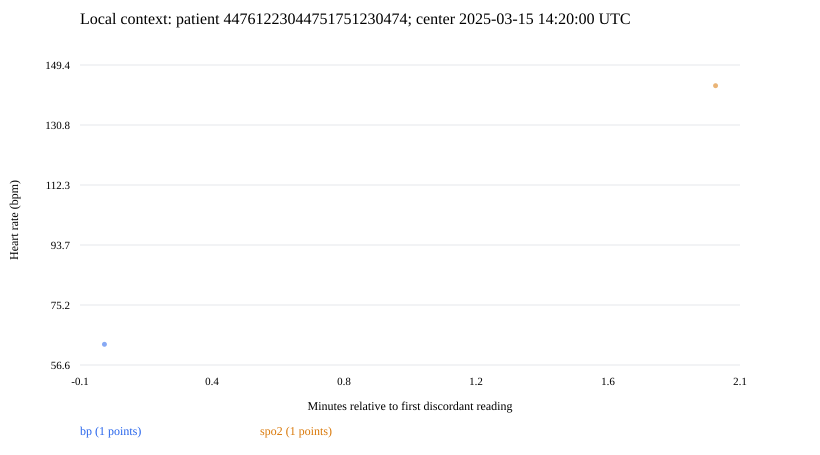

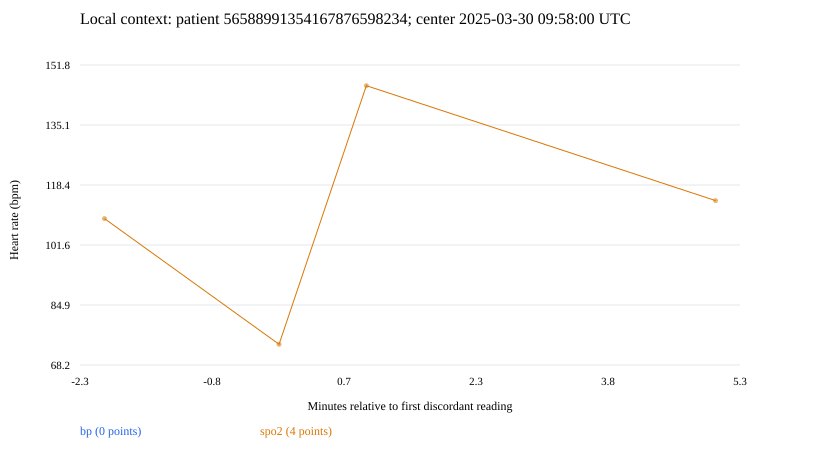

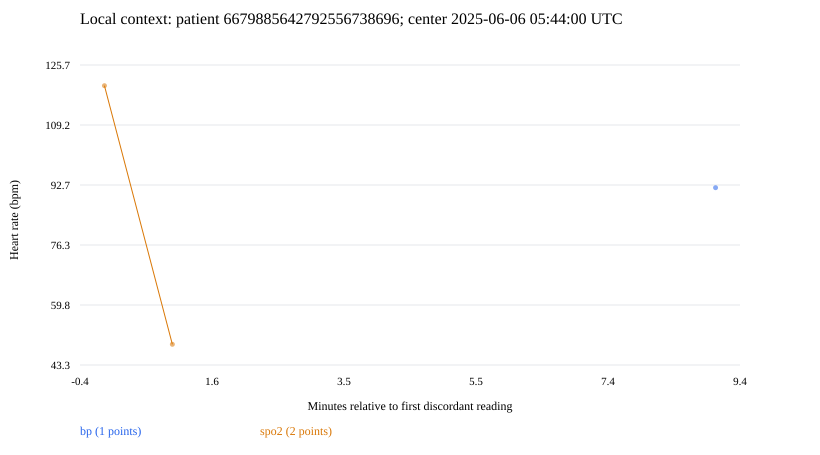

In [15]:
hr_review_reasons=defaultdict(set)
for f in hr_quality_flags:hr_review_reasons[f['row_id']].add(f['reason'])
for group in hr_exact_candidates:
    for row_id in group['row_ids']:hr_review_reasons[row_id].add('exact_measurement_candidate')
for event in hr_event_repeats:
    for row_id in event['row_ids']:hr_review_reasons[row_id].add('event_key_'+event['classification'])
hr_discordant_pairs=[p for p in hr_pairs if p['time_minutes']<=2 and p['absolute_difference']>10]
for p in hr_discordant_pairs:
    for key in ('row_id_1','row_id_2'):hr_review_reasons[p[key]].add('nearby_difference_gt10_within2min')
hr_robust_summary=[]
for s in HR_SOURCES:
    rows=[r for r in hr_eligible if r['source']==s]
    values=[r['value'] for r in rows]
    median=hr_q(values,.5)
    mad=hr_q([abs(v-median) for v in values],.5) if values else None
    hr_robust_summary.append(dict(source=s,median=median,mad=mad,scaled_mad=1.4826*mad if mad is not None else None))
    for r in rows:
        if r['value']<40 or r['value']>130:hr_review_reasons[r['row_id']].add('outside_exploratory_40_130')
        if mad and abs(r['value']-median)>5*1.4826*mad:hr_review_reasons[r['row_id']].add('source_deviation_gt5_scaled_MAD')
hr_neighbors={}
for rows in hr_patient_source_rows.values():
    for i,r in enumerate(rows):
        previous=rows[i-1] if i else None
        following=rows[i+1] if i+1<len(rows) else None
        hr_neighbors[r['row_id']]=dict(previous_hr=previous['value'] if previous else None,
            previous_gap_minutes=(r['time']-previous['time']).total_seconds()/60 if previous else None,
            next_hr=following['value'] if following else None,
            next_gap_minutes=(following['time']-r['time']).total_seconds()/60 if following else None)
hr_review_queue=[]
for row_id,reasons in sorted(hr_review_reasons.items()):
    r=hr_by_id[row_id]
    if 'event_key_changed_payload' in reasons:
        action='Investigate event versions; do not choose by value similarity'
    elif 'event_key_identical_retained_payload' in reasons:
        action='Candidate record deduplication; confirm event-key semantics and original payload'
    elif 'exact_measurement_candidate' in reasons:
        action='Compare full acquisition and raw metadata; distinct IDs may be genuine repeats'
    else:
        action='Retain and flag pending review; do not average discordant values'
    hr_review_queue.append(dict(row_id=row_id,patient=r['patient'],source=r['source'],time=r['time'],hr=r['value'],
        json_id=r['json_id'],transm_id=r['transm_id'],reasons=tuple(sorted(reasons)),proposed_action=action,
        device=hr_metadata_by_id.get(row_id,{}).get('device'),serial=hr_metadata_by_id.get(row_id,{}).get('serial'),
        **hr_neighbors.get(row_id,{})))
hr_table('Descriptive robust reference statistics (not fitted cleaning rules)',hr_robust_summary)
hr_table('Review reason counts (one observation may have several)',
    [dict(reason=k,observations=v) for k,v in Counter(reason for reasons in hr_review_reasons.values() for reason in reasons).most_common()])
hr_table('Full observation review queue',hr_review_queue,limit=25)
hr_table('Most discordant nearby pairs',sorted(hr_discordant_pairs,key=lambda p:p['absolute_difference'],reverse=True),limit=20,
    columns=['patient','row_id_1','row_id_2','comparison','time_minutes','hr_1','hr_2','absolute_difference'])
hr_consistent_candidates=[p for p in hr_pairs if p['time_minutes']<=2 and p['absolute_difference']<=5]
hr_consistent_sample=random.Random(HR_SEED).sample(hr_consistent_candidates,min(10,len(hr_consistent_candidates)))
hr_table('Random sample of apparently consistent pairs',hr_consistent_sample,limit=10,
    columns=['patient','row_id_1','row_id_2','comparison','time_minutes','hr_1','hr_2','absolute_difference'])
hr_timeline_patients=set()
for p in sorted(hr_discordant_pairs,key=lambda p:p['absolute_difference'],reverse=True):
    if p['patient'] in hr_timeline_patients:continue
    hr_timeline_patients.add(p['patient'])
    center=min(p['time_1'],p['time_2'])
    rows=[r for r in hr_patient_rows[p['patient']] if abs((r['time']-center).total_seconds())<=15*60]
    hr_plot(f'Local context: patient {p["patient"]}; center {center} UTC',
        [(s,[((r['time']-center).total_seconds()/60,r['value']) for r in rows if r['source']==s]) for s in HR_SOURCES],
        'Minutes relative to first discordant reading','Heart rate (bpm)',connect=True)
    if len(hr_timeline_patients)>=3:break
hr_text(f'{len(hr_review_queue)} distinct observations have at least one review flag. '
        'Neighboring measurements after the flagged event are for retrospective review only; they must not enter a real-time prediction.')


### 8. Traceable analysis representations and prediction-time safeguards

Preserve `df`, observation IDs, pair evidence, review reasons, and episode membership.
The objects below expose the audit tables for downstream work. The conservative
analysis view retains every structurally usable HR observation, including flagged
values; it is **not a clinically adjudicated clean dataset**. Invalid structure is
reported separately rather than silently discarded. No source is automatically
preferred and no imputation is fitted here.

Demonstrate features at each patient's last observed acquisition time, using only
observations at or before that cutoff in a 24-hour lookback. Keep separate recent
BP/SpO₂ values, their ages, counts, ranges, and discordance. This is an illustrative
feature snapshot, not a training cohort: outcomes, prediction times, horizon, and
availability/registration semantics have not been specified. A production model
must use availability time when acquisition precedes delivery. Learned cleaning,
imputation, and scaling must be fitted within training folds; use patient-separated
or temporal evaluation according to the intended deployment. Do not use future
neighbors or an episode that extends beyond the cutoff.
The retrospective review flags (including whole-dataset MAD and pair involvement)
are deliberately excluded from model features: they can depend on future readings.
The availability proxy also excludes a record whose last known update occurs after
the cutoff. It does not reconstruct historical versions. If simultaneous latest
values disagree within a source, the latest-HR feature is left missing and a tie
indicator is retained instead of selecting an arbitrary value.


In [16]:
hr_analysis_observations=[dict(row_id=r['row_id'],patient=r['patient'],source=r['source'],
    time=r['time'],hr_bpm=r['value'],json_id=r['json_id'],transm_id=r['transm_id'],
    review_reasons=tuple(sorted(hr_review_reasons.get(r['row_id'],set())))) for r in hr_eligible]

def hr_features_at(patient, cutoff, lookback_hours=24, require_recorded_availability=False):
    cutoff=hr_time(cutoff)
    if cutoff is None:raise ValueError('A valid prediction cutoff is required')
    if lookback_hours<=0:raise ValueError('lookback_hours must be positive')
    rows=[r for r in hr_patient_rows.get(patient,[]) if cutoff-timedelta(hours=lookback_hours)<=r['time']<=cutoff]
    excluded_unknown_availability=0
    excluded_late_availability=0
    if require_recorded_availability:
        available=[]
        for r in rows:
            metadata=hr_metadata_by_id.get(r['row_id'],{})
            # Delivery/registration, creation, and any known update precede cutoff.
            # These are a conservative proxy, not confirmed production semantics.
            times=[metadata.get('registration'),metadata.get('created')]
            if any(t is None for t in times):
                excluded_unknown_availability+=1
            elif max(times+[metadata['updated']] if metadata.get('updated') else times)<=cutoff:
                available.append(r)
            else:
                excluded_late_availability+=1
        rows=available
    result=dict(patient=patient,cutoff=cutoff,lookback_hours=lookback_hours,
                availability_required=require_recorded_availability,
                excluded_unknown_availability=excluded_unknown_availability,
                excluded_late_availability=excluded_late_availability)
    for s in HR_SOURCES:
        selected=[r for r in rows if r['source']==s]
        latest=max(selected,key=lambda r:(r['time'],r['row_id'])) if selected else None
        same_latest=[r for r in selected if latest and r['time']==latest['time']]
        latest_values={r['value'] for r in same_latest}
        result.update({f'{s}_count':len(selected),f'{s}_latest_hr':next(iter(latest_values)) if len(latest_values)==1 else None,
            f'{s}_latest_time_ties':len(same_latest),
            f'{s}_latest_discordant':len(latest_values)>1,
            f'{s}_age_minutes':(cutoff-latest['time']).total_seconds()/60 if latest else None,
            f'{s}_median':hr_q([r['value'] for r in selected],.5),
            f'{s}_range':max(r['value'] for r in selected)-min(r['value'] for r in selected) if selected else None})
    ids={r['row_id'] for r in rows}
    known_pairs=[p for p in hr_pairs if p['row_id_1'] in ids and p['row_id_2'] in ids
                 and not p['same_source'] and p['time_minutes']<=2]
    result['cross_source_discordant_pairs_gt10']=sum(p['absolute_difference']>10 for p in known_pairs)
    result['contributing_row_ids']=tuple(r['row_id'] for r in rows)
    return result

hr_feature_snapshots=[]
for patient,rows in sorted(hr_patient_rows.items()):
    cutoff=rows[-1]['time']
    hr_feature_snapshots.append(hr_features_at(patient,cutoff,require_recorded_availability=True))
hr_table('Illustrative features at each patient’s final acquisition cutoff (availability proxy enforced)',
         hr_feature_snapshots,limit=15,
         columns=['patient','cutoff','bp_count','spo2_count','bp_latest_hr','spo2_latest_hr','bp_age_minutes',
                  'spo2_age_minutes','cross_source_discordant_pairs_gt10','excluded_unknown_availability'])
hr_text(f'Availability proxy excludes {sum(r["excluded_late_availability"] for r in hr_feature_snapshots)} '
        f'late-delivered/created observations and {sum(r["excluded_unknown_availability"] for r in hr_feature_snapshots)} '
        'observations with unknown availability across these illustrative snapshots. '
        'Acquisition-only features can be requested with require_recorded_availability=False for retrospective exploration, '
        'but that setting does not establish real-time availability.')
hr_audit_tables=dict(observations=hr_analysis_observations,quality_flags=hr_quality_flags,
    event_repeats=hr_event_repeats,exact_candidates=hr_exact_candidates,raw_metadata=hr_metadata,
    pairs=hr_pairs,threshold_sensitivity=hr_sensitivity,agreement_pairs=hr_matches,
    agreement_summary=hr_agreement_summary,agreement_by_patient=hr_agreement_by_patient,
    episodes=hr_candidate_episodes,review_queue=hr_review_queue,feature_snapshots=hr_feature_snapshots)
hr_table('Available full audit tables', [dict(object=name,rows=len(rows)) for name,rows in hr_audit_tables.items()])


patient,cutoff,bp_count,spo2_count,bp_latest_hr,spo2_latest_hr,bp_age_minutes,spo2_age_minutes,cross_source_discordant_pairs_gt10,excluded_unknown_availability
10215810359558408931496,2025-05-22 05:48:00,1,1,52,54,"1,387","1,386",0,0
11063043325284003255284,2026-02-27 07:08:00,1,1,59,65,0,32,0,0
14821188439400459951949,2025-09-12 05:07:00,2,2,62,77,0,18,0,0
16457305258260151724820,2025-12-21 06:30:00,0,1,—,92,—,13,0,0
1685041082445787054942,2026-02-21 09:44:00,3,0,91,—,0,—,0,0
21641783462018789544099,2025-11-10 03:37:00,0,3,—,70,—,107,0,0
22663991724083203598201,2026-03-18 06:10:00,1,1,61,67,"1,372","1,437",0,0
24237081325524430327506,2025-12-22 12:14:00,1,1,76,59,0,14,0,0
25091128815292953435003,2026-01-20 04:17:00,0,0,—,—,—,—,0,0
26287715369837557488638,2025-08-26 07:22:00,1,1,65,73,0,63,0,0


object,rows
observations,19292
quality_flags,0
event_repeats,0
exact_candidates,11
raw_metadata,19292
pairs,5050
threshold_sensitivity,48
agreement_pairs,1006
agreement_summary,4
agreement_by_patient,29


### Validation and computed findings

The checks below verify pair boundaries, one-to-one matching, complete episode
membership, bounded maximum-span episodes, time-safe feature membership, and input
immutability. They validate bookkeeping; they cannot validate clinical accuracy.
The computed summary reports the current data rather than hard-coding expected counts.


In [17]:
assert hashlib.sha256(repr(df.to_dict('records')).encode()).hexdigest()==hr_input_digest, 'Input df changed'
assert len({r['row_id'] for r in hr_eligible})==len(hr_eligible)
for p in hr_pairs:
    a,b=hr_by_id[p['row_id_1']],hr_by_id[p['row_id_2']]
    assert a['patient']==b['patient'] and 0<=p['time_minutes']<=max(HR_TIME_WINDOWS)
    assert p['absolute_difference']==abs(a['value']-b['value'])
for window,pairs in hr_matched_by_window.items():
    ids=[p[k] for p in pairs for k in ('row_id_1','row_id_2')]
    assert len(ids)==len(set(ids)) and all(p['time_minutes']<=window for p in pairs)
for policy,episodes in hr_episodes_by_policy.items():
    members=[row_id for episode in episodes for row_id in episode['row_ids']]
    assert sorted(members)==sorted(r['row_id'] for r in hr_eligible)
assert all(e['span_minutes']<=HR_EPISODE_MINUTES for e in hr_candidate_episodes)
for features in hr_feature_snapshots:
    assert all(hr_by_id[row_id]['time']<=features['cutoff'] for row_id in features['contributing_row_ids'])
    for row_id in features['contributing_row_ids']:
        m=hr_metadata_by_id[row_id]
        assert m['registration']<=features['cutoff'] and m['created']<=features['cutoff']
        assert m.get('updated') is None or m['updated']<=features['cutoff']
hr_text('All audit consistency checks passed; df remains unchanged.')
hr_same_time_cross=[p for p in hr_pairs if not p['same_source'] and p['time_minutes']==0]
hr_text(f'Observed findings: {len(hr_present):,} reported HR observations; '
        f'{len(hr_patient_rows)} patients with structurally usable HR; '
        f'{len(hr_event_repeats)} repeated provisional event keys; '
        f'{len(hr_exact_candidates)} exact same-source measurement candidate groups; '
        f'{len(hr_same_time_cross)} same-time cross-source pairs, of which '
        f'{sum(p["absolute_difference"]==0 for p in hr_same_time_cross)} agree exactly and '
        f'{sum(p["absolute_difference"]>10 for p in hr_same_time_cross)} differ by more than 10 bpm. '
        f'Two-minute time-only matching gives {len(hr_matches)} pairs; estimated SpO₂-minus-BP bias is '
        f'{hr_fmt(hr_primary_stats["bias_spo2_minus_bp"])} bpm and approximate limits of agreement are '
        f'{hr_fmt(hr_primary_stats["loa_lower"])} to {hr_fmt(hr_primary_stats["loa_upper"])} bpm.')
hr_text('Recommended next decision: adjudicate the review queue and confirm timestamp/event-key semantics with the data provider. '
        'Keep source-specific measurements and flags for initial modelling. Do not automatically merge distinct acquisitions, '
        'prefer one source, or treat the exploratory thresholds as medical exclusion rules. '
        'A final prediction-ready cohort additionally requires an outcome, prediction horizon, and confirmed data-availability times.')
